# Part B – Strategic Resource Negotiation

Implementation of the adversarial negotiation engine for the **Strategic Diplomacy AI** project.

This notebook contains:

* Minimax with Alpha–Beta pruning (depth‑limited)
* Three custom evaluation functions
* Utilities for running self‑play simulations, collecting performance metrics and visualising small game trees

*Only the standard libraries `random`, `math`, `copy`, `time`, together with `numpy` and `matplotlib` are used (as permitted).*

In [1]:

import random, math, copy, time
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict


In [2]:

# Negotiation actions
ACTIONS = ['Offer', 'Threaten', 'Bluff', 'Concede', 'Delay']

# Resource indices for convenience
RESOURCES = ['Energy', 'Water', 'Technology']

# Maximum utility (per resource) used for normalisation
MAX_URGENCY = 10


In [3]:

class Faction:
    """Represents a rival faction participating in the summit."""
    def __init__(self, name, urgencies):
        """`urgencies` is a dict mapping each resource to an int 0‑10."""
        self.name = name
        self.urgencies = urgencies
        self.fatigue = 0           # grows when the faction has back‑to‑back sessions
        self.history = defaultdict(int)  # counts of past positive / negative encounters

    def __repr__(self):
        return f"Faction({self.name})"


In [4]:

class NegotiationState:
    """Immutable representation of a negotiation game node."""
    def __init__(self, p1, p2, turn, depth, max_depth, history=None, fatigue=None, last_action=None):
        self.p1 = p1    # type: Faction
        self.p2 = p2    # type: Faction
        self.turn = turn        # 0 → p1 to act, 1 → p2 to act
        self.depth = depth
        self.max_depth = max_depth
        self.last_action = last_action
        self.history = copy.deepcopy(history) if history else []
        self.fatigue = fatigue if fatigue else {p1.name: p1.fatigue, p2.name: p2.fatigue}

    def is_terminal(self):
        return self.depth >= self.max_depth or (self.last_action == 'Concede' and self.history)

    def next_player(self):
        return self.p1 if self.turn == 0 else self.p2

    def opponent(self):
        return self.p2 if self.turn == 0 else self.p1

    def successors(self):
        """Generate successor states for each legal action."""
        succs = []
        for act in ACTIONS:
            # simple rule: cannot Bluff twice in a row
            if act == 'Bluff' and self.last_action == 'Bluff':
                continue
            new_hist = self.history + [(self.turn, act)]
            succs.append(NegotiationState(
                self.p1, self.p2,
                1 - self.turn,
                self.depth + 1,
                self.max_depth,
                history=new_hist,
                fatigue=self.fatigue,
                last_action=act
            ))
        return succs


In [5]:

# --- Evaluation functions ---
def _base_score(faction, opp, history):
    """Generic linear score: resource urgencies minus opponent benefit."""
    return sum(faction.urgencies[r] for r in RESOURCES) - 0.5*sum(opp.urgencies[r] for r in RESOURCES)

def eval_basic(state, maximizing_for):
    """Evaluation 1: purely static urgency‑based."""
    p_max = state.p1 if maximizing_for == 0 else state.p2
    p_opp = state.p2 if maximizing_for == 0 else state.p1
    return _base_score(p_max, p_opp, state.history)

def eval_fatigue(state, maximizing_for):
    """Evaluation 2: urgency minus fatigue penalty."""
    p_max = state.p1 if maximizing_for == 0 else state.p2
    p_opp = state.p2 if maximizing_for == 0 else state.p1
    fatigue_penalty = state.fatigue[p_max.name] * 1.5
    return _base_score(p_max, p_opp, state.history) - fatigue_penalty

def eval_history(state, maximizing_for):
    """Evaluation 3: adds trust / rivalry based on past Bluff or Threaten."""
    p_max = state.p1 if maximizing_for == 0 else state.p2
    p_opp = state.p2 if maximizing_for == 0 else state.p1
    trust = 0
    for turn, act in state.history:
        if turn == (0 if maximizing_for == 0 else 1):
            if act in ('Offer', 'Concede'):
                trust += 2
            elif act == 'Threaten':
                trust -= 3
            elif act == 'Bluff':
                trust -= 4
        else:
            # opponent actions weigh half
            if act in ('Offer', 'Concede'):
                trust += 1
            elif act == 'Threaten':
                trust -= 1.5
            elif act == 'Bluff':
                trust -= 2
    return _base_score(p_max, p_opp, state.history) + trust


In [6]:

def minimax(state, depth, alpha, beta, maximizing_player, eval_fn, stats):
    # Increment node count
    stats['nodes'] += 1

    if depth == 0 or state.is_terminal():
        if maximizing_player == 0:
            return None, eval_fn(state, 0)
        else:
            return None, eval_fn(state, 1)

    best_action = None
    if maximizing_player == 0:
        max_eval = -math.inf
        for succ in state.successors():
            _, val = minimax(succ, depth-1, alpha, beta, 1, eval_fn, stats)
            if val > max_eval:
                max_eval = val
                best_action = succ.last_action
            alpha = max(alpha, val)
            if beta <= alpha:
                break
        return best_action, max_eval
    else:
        min_eval = math.inf
        for succ in state.successors():
            _, val = minimax(succ, depth-1, alpha, beta, 0, eval_fn, stats)
            if val < min_eval:
                min_eval = val
                best_action = succ.last_action
            beta = min(beta, val)
            if beta <= alpha:
                break
        return best_action, min_eval


In [7]:

def simulate_session(f1, f2, eval_fn, search_depth=4):
    """Run a single negotiation session between two factions using the given evaluation function."""
    root = NegotiationState(f1, f2, turn=0, depth=0, max_depth=search_depth)
    stats = {'nodes': 0}
    t0 = time.time()
    action, utility = minimax(root, search_depth, -math.inf, math.inf, 0, eval_fn, stats)
    elapsed = time.time() - t0
    return {'first_action': action, 'utility': utility, 'nodes': stats['nodes'], 'time': elapsed}


In [8]:

# ==== Demo with three evaluation strategies ====
random.seed(42)
fA = Faction('Alpha', {'Energy': 8, 'Water': 2, 'Technology': 5})
fB = Faction('Beta',  {'Energy': 3, 'Water': 7, 'Technology': 6})

eval_fns = [eval_basic, eval_fatigue, eval_history]
labels = ['Basic', 'Fatigue', 'History']

results = []
for fn, label in zip(eval_fns, labels):
    res = simulate_session(fA, fB, fn)
    res['label'] = label
    results.append(res)
    print(f"{label} ⇒ first action: {res['first_action']}, utility: {res['utility']:.2f}, nodes: {res['nodes']}, time: {res['time']*1000:.1f} ms")


Basic ⇒ first action: Concede, utility: 8.50, nodes: 104, time: 1.3 ms
Fatigue ⇒ first action: Concede, utility: 8.50, nodes: 104, time: 1.0 ms
History ⇒ first action: Concede, utility: 9.50, nodes: 118, time: 1.1 ms


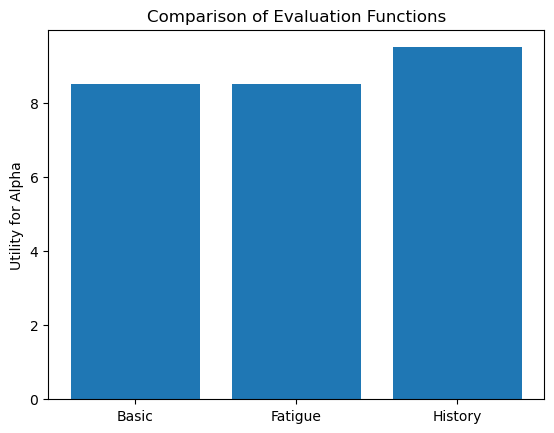

In [9]:

# Plot utility comparison
utils = [r['utility'] for r in results]
fig, ax = plt.subplots()
ax.bar(labels, utils)
ax.set_ylabel('Utility for Alpha')
ax.set_title('Comparison of Evaluation Functions')
plt.show()


In [10]:
def draw_small_tree(state, depth=2, eval_fn=None, maximizing_faction=None):
    """Draws a game tree up to depth 2 without using gc. Assumes tree is small."""
    if depth > 2:
        raise ValueError("Depth too large for visual helper")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axis('off')

    positions = {}
    edges = {}
    labels = {}

    def traverse(node, x, y, dx, current_depth):
        node_id = id(node)
        positions[node_id] = (x, y)
        if node.is_terminal():
            val = eval_fn(node, maximizing_faction) if eval_fn else ''
            labels[node_id] = f'T\n{val:.1f}' if isinstance(val, (int, float)) else 'T'
            return
        else:
            labels[node_id] = ''
        if current_depth >= depth:
            return

        children = node.successors()
        n = len(children)
        child_dx = dx / max(n, 1)
        for i, child in enumerate(children):
            child_x = x - dx/2 + child_dx/2 + i * child_dx
            child_y = y - 1
            edges[(node_id, id(child))] = (x, y, child_x, child_y)
            traverse(child, child_x, child_y, child_dx, current_depth + 1)

    traverse(state, 0, 0, 6, 0)

    # Draw edges
    for (parent_id, child_id), (x0, y0, x1, y1) in edges.items():
        ax.plot([x0, x1], [y0, y1], 'k-', lw=1)

    # Draw nodes
    for node_id, (x, y) in positions.items():
        label = labels.get(node_id, '')
        ax.text(x, y, label, ha='center', va='center',
                bbox=dict(boxstyle='circle', fc='lightgray', ec='black'))

    plt.title("Negotiation Tree (depth ≤ 2)")
    plt.show()


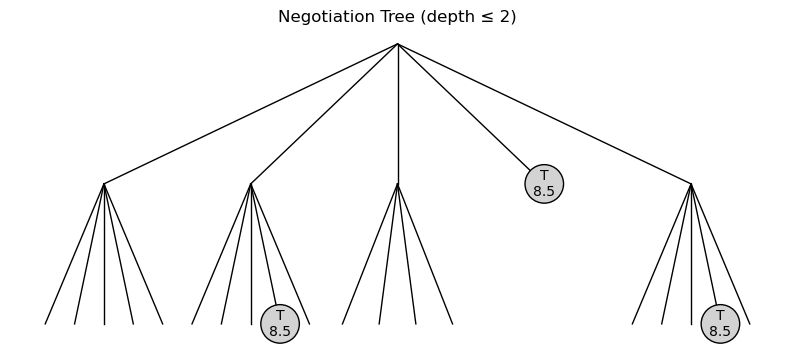

In [11]:

# Visualise a small tree (depth 2) for the Basic evaluation
root = NegotiationState(fA, fB, turn=0, depth=0, max_depth=3)
draw_small_tree(root, depth=2, eval_fn=eval_basic)




Session 1: Gamma vs Delta
  Basic    → util: +9.00, nodes:  104, time:    1.0 ms
  Fatigue  → util: +9.00, nodes:  104, time:    0.9 ms
  History  → util: +10.00, nodes:  118, time:    1.1 ms

Session 2: Epsilon vs Zeta
  Basic    → util: +9.00, nodes:  104, time:    0.9 ms
  Fatigue  → util: +9.00, nodes:  104, time:    0.9 ms
  History  → util: +10.00, nodes:  114, time:    1.1 ms

Session 3: Alpha vs Beta
  Basic    → util: +7.50, nodes:   72, time:    0.7 ms
  Fatigue  → util: +7.50, nodes:   72, time:    0.6 ms
  History  → util: +8.50, nodes:  120, time:    1.1 ms


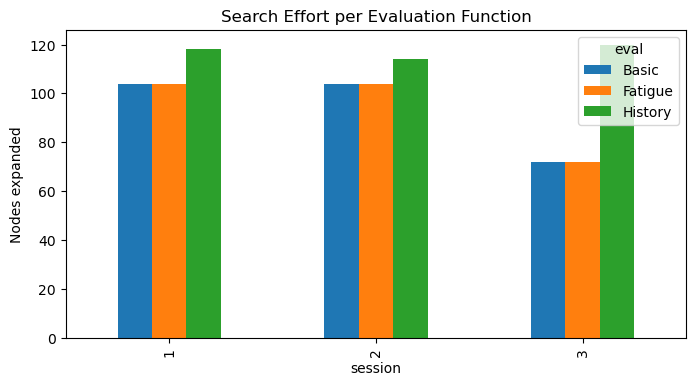

In [12]:

# === Benchmark 3 different sessions ===
sessions = [
    (Faction('Gamma', {'Energy':4,'Water':9,'Technology':3}),
     Faction('Delta', {'Energy':6,'Water':4,'Technology':7})),
    (Faction('Epsilon', {'Energy':9,'Water':1,'Technology':4}),
     Faction('Zeta', {'Energy':2,'Water':8,'Technology':6})),
    (Faction('Alpha', {'Energy':5,'Water':5,'Technology':5}),
     Faction('Beta',  {'Energy':5,'Water':5,'Technology':5}))
]

all_stats = []
for idx, (f1, f2) in enumerate(sessions, 1):
    print(f"\nSession {idx}: {f1.name} vs {f2.name}")
    for fn, label in zip(eval_fns, labels):
        stat = simulate_session(f1, f2, fn)
        stat.update({'session': idx, 'eval': label})
        all_stats.append(stat)
        print(f"  {label:<8} → util: {stat['utility']:+.2f}, nodes: {stat['nodes']:4d}, time: {stat['time']*1000:6.1f} ms")

# Plot nodes expanded per evaluation
import pandas as pd
df = pd.DataFrame(all_stats)
pivot = df.pivot_table(index='session', columns='eval', values='nodes')
pivot.plot(kind='bar', figsize=(8,4))
plt.ylabel('Nodes expanded')
plt.title('Search Effort per Evaluation Function')
plt.show()
